# RQ2 - Does *how* a college spends predict whether students finish?

**Question.** Holding an institution's total scale fixed, is spending more on
instruction (versus administration) associated with a higher six-year
graduation rate?

**Design.** Institution and year fixed effects; clustered SEs.

**Sample.** Four-year institutions (sectors 1-3), 2004-2017.

**What we do not control for.** There is no working enrolment-by-race endpoint
- `fall-enrollment/{year}/race/` returns HTTP 500 and the plain
`fall-enrollment` table has no race column at all. Rather than invent a
diversity control, we use the Pell share as the student-composition measure
and say so.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import pandas as pd
from src import panels
from src.regression import panel_ols
pd.set_option("display.width", 120)

In [2]:
p = panels.rq2()
print(f"{len(p):,} institution-years, {p.unitid.nunique():,} institutions, {p.year.min()}-{p.year.max()}")
p[["grad_rate", "instr_per_fte_real", "admin_per_fte_real", "pct_pell", "fte"]].describe().round(2)

26,347 institution-years, 2,571 institutions, 2004-2017


,grad_rate,instr_per_fte_real,admin_per_fte_real,pct_pell,fte
count,26347.00,26347.00,26347.00,19580.00,26347.00
mean,0.51,10255.67,8000.45,0.40,5423.66
std,0.20,9148.27,7311.21,0.19,8077.62
min,0.01,23.56,21.66,0.00,100.00
25%,0.36,6123.05,4416.67,0.26,1018.00
50%,0.50,8288.24,6319.77,0.37,2294.00
75%,0.65,11480.00,9180.37,0.51,5962.50
max,1.00,305619.74,194998.68,1.00,127781.00


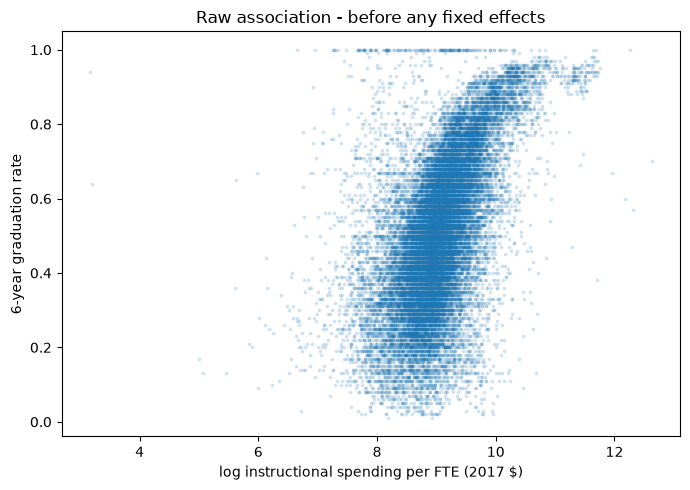

In [3]:
ax = p.plot.scatter("log_instr_per_fte", "grad_rate", s=3, alpha=.15, figsize=(7, 5))
ax.set(xlabel="log instructional spending per FTE (2017 $)",
       ylabel="6-year graduation rate",
       title="Raw association - before any fixed effects")
plt.tight_layout(); plt.show()

The raw cloud slopes upward, but most of that is *between* institutions:
well-resourced colleges both spend more and enrol better-prepared students.
Institution fixed effects throw that comparison away and ask a harder
question - when *this* college changes its spending mix, does *its*
graduation rate move?

In [4]:
# No sector dummies here: sector almost never changes within an
# institution, so the institution fixed effects already absorb them.
res = panel_ols(p, "grad_rate",
                ["log_instr_per_fte", "log_admin_per_fte", "pct_pell", "log_fte"],
                name="RQ2")
print(res.summary())

RQ2: 19,580 obs, 2,538 institutions, within R2=0.002
                     coef  stderr   tstat  pvalue  ci_low  ci_high
log_instr_per_fte  0.0011  0.0112  0.0995  0.9208 -0.0208   0.0230
log_admin_per_fte  0.0012  0.0093  0.1329  0.8943 -0.0170   0.0194
pct_pell          -0.0596  0.0199 -2.9915  0.0028 -0.0986  -0.0205
log_fte            0.0182  0.0074  2.4428  0.0146  0.0036   0.0328


The outcome is a proportion, so a coefficient of 0.01 means one percentage
point. Read the instruction and administration coefficients together: they
answer "shift a dollar from one to the other", which is the actual policy
lever a board controls.

If both are indistinguishable from zero, that is a finding, not a failure -
it says within-institution spending shifts of the size actually observed do
not move completion much over this period.

In [5]:
for f in panels.save(p, "rq2_panel"):
    print(f)

results/rq2_panel.parquet
results/rq2_panel.csv
results/rq2_panel.dta
